# Домашнее задание

Математический анализ
69 баллов

**Задача 1** (14 баллов)

Найдите экстремумы функции:

$$
f(x, y, z)=2 x^3+2 x y+2 x z+y^2+z^2+2 y-8 .
$$

Распишите подробное решение.

In [1]:
import sympy as sp
from IPython.display import display

In [5]:
x, y, z = sp.symbols('x y z', real=True)
variables = (x, y, z)

f = 2*x**3 + 2*x*y + 2*x*z + y**2 + z**2 + 2*y - 8
display(f)

2*x**3 + 2*x*y + 2*x*z + y**2 + 2*y + z**2 - 8

In [6]:
# 1. Частные производные
gradient = [sp.diff(f, v) for v in variables]

print("\nЧастные производные:")
for v, derivative in zip(variables, gradient):
    print(f"df/d{v} = {derivative}")


Частные производные:
df/dx = 6*x**2 + 2*y + 2*z
df/dy = 2*x + 2*y + 2
df/dz = 2*x + 2*z


In [7]:
# 2. Решаем систему: все частные производные равны нулю
points = sp.solve(gradient, variables, dict=True)

print("\nСтационарные точки:")
for point in points:
    print(tuple(point[v] for v in variables))


Стационарные точки:
(-1/3, -2/3, 1/3)
(1, -2, -1)


In [8]:
# 3. Матрица вторых производных
H = sp.hessian(f, variables)

print("\nМатрица Гессе:")
display(H)



Матрица Гессе:


Matrix([
[12*x, 2, 2],
[   2, 2, 0],
[   2, 0, 2]])

In [9]:
# 4. Исследуем каждую точку
for point in points:
    coordinates = tuple(point[v] for v in variables)
    H_point = H.subs(point)
    value = sp.simplify(f.subs(point))

    print(f"\nТочка {coordinates}")
    print("Матрица Гессе в точке:")
    display(H_point)

    # Угловые главные миноры
    minors = [
        sp.simplify(H_point[:i, :i].det())
        for i in range(1, 4)
    ]
    print("Главные угловые миноры:", minors)

    # Собственные значения симметричной матрицы Гессе
    eigenvalues = list(H_point.eigenvals())

    if all(e > 0 for e in eigenvalues):
        result = "Строгий локальный минимум"
    elif all(e < 0 for e in eigenvalues):
        result = "Строгий локальный максимум"
    elif any(e > 0 for e in eigenvalues) and any(e < 0 for e in eigenvalues):
        result = "Седловая точка — экстремума нет"
    else:
        result = "Требуется дополнительное исследование"

    print("Результат:", result)
    print("Значение функции:", value)


Точка (-1/3, -2/3, 1/3)
Матрица Гессе в точке:


Matrix([
[-4, 2, 2],
[ 2, 2, 0],
[ 2, 0, 2]])

Главные угловые миноры: [-4, -12, -32]
Результат: Седловая точка — экстремума нет
Значение функции: -233/27

Точка (1, -2, -1)
Матрица Гессе в точке:


Matrix([
[12, 2, 2],
[ 2, 2, 0],
[ 2, 0, 2]])

Главные угловые миноры: [12, 20, 32]
Результат: Строгий локальный минимум
Значение функции: -11


In [10]:
# 5. Проверяем глобальные экстремумы
f_line = f.subs({y: 0, z: 0})

print("\nНа прямой y = z = 0:")
display(f_line)

print("Предел при x → +∞:", sp.limit(f_line, x, sp.oo))
print("Предел при x → -∞:", sp.limit(f_line, x, -sp.oo))
print("Глобальных минимума и максимума нет.")


На прямой y = z = 0:


2*x**3 - 8

Предел при x → +∞: oo
Предел при x → -∞: -oo
Глобальных минимума и максимума нет.


**Задача 2** (25 баллов)

Найдите условные экстремумы функции:

$$
f(x, y)=4 x+8 y, y^2-2 x y+5=0
$$

Вычислите результат самостоятельно (вручную) и с помощью Python. Сравните результаты.

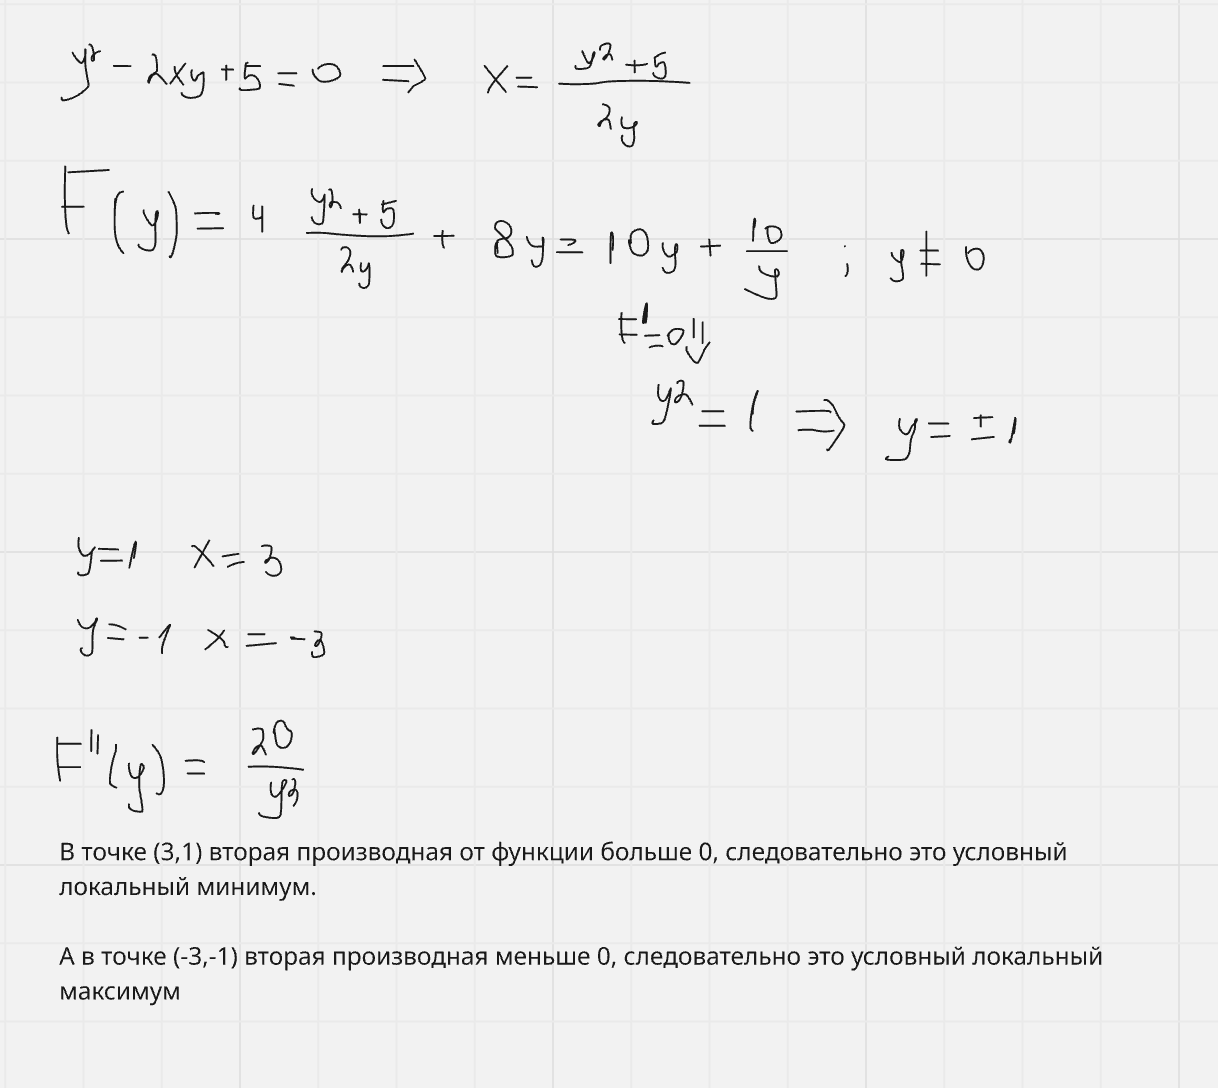

In [12]:
x, y = sp.symbols('x y', real=True)

f = 4*x + 8*y
g = y**2 - 2*x*y + 5

In [13]:
# Выражаем x из ограничения (y != 0)
x_expr = sp.solve(g, x)[0]
print("x из ограничения:")
display(x_expr)

x из ограничения:


(y**2 + 5)/(2*y)

In [14]:
# Подставляем x в исходную функцию
F = sp.simplify(f.subs(x, x_expr))
print("Функция одной переменной:")
display(F)

Функция одной переменной:


10*y + 10/y

In [15]:
# Первая и вторая производные
dF = sp.diff(F, y)
ddF = sp.diff(F, y, 2)

In [16]:
print("Первая производная:")
display(dF)

Первая производная:


10 - 10/y**2

In [17]:
print("Вторая производная:")
display(ddF)

Вторая производная:


20/y**3

In [19]:
# Находим и исследуем стационарные точки
for y0 in sp.solve(dF, y):
    x0 = sp.simplify(x_expr.subs(y, y0))
    value = f.subs({x: x0, y: y0})
    second = ddF.subs(y, y0)

    print(f"\nТочка: ({x0}, {y0})")
    print("Проверка ограничения:", g.subs({x: x0, y: y0}))
    print("Вторая производная:", second)

    if second > 0:
        print("Условный локальный минимум")
    elif second < 0:
        print("Условный локальный максимум")

    print("Значение функции:", value)


Точка: (-3, -1)
Проверка ограничения: 0
Вторая производная: -20
Условный локальный максимум
Значение функции: -20

Точка: (3, 1)
Проверка ограничения: 0
Вторая производная: 20
Условный локальный минимум
Значение функции: 20


**Задача 3** (30 баллов)

Вам предложены данные с информацией о успеваемости студентов:

Независимые переменные:
* Hours Studied: Общее количество часов, потраченных на учебу каждым студентом.
* Previous Scores: Баллы, полученные студентами на предыдущих экзаменах.
* Sleep Hours: Среднее количество часов сна студента в сутки.
* Sample Question Papers Practiced: Количество пробных экзаменационных работ, с которыми студент занимался.
  
Целевая переменная:
* Performance Index: Показатель общей успеваемости каждого студента. Индекс успеваемости отражает академическую успеваемость студента и округляется до ближайшего целого числа. Индекс варьируется от 10 до 100, при этом более высокие значения свидетельствуют о более высокой успеваемости.

**Решите задачу линейной регрессии, реализовав градиентный спуск самостоятельно, не используя готовое решение из какой-либо библиотеки.**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
path = "/Users/pavelsergusov/Desktop/git_pavel/Maga/ТерВер/asset-v1_skillfactory+MIFIML-1sem+2025+type@asset+block@Математическии__анализ_и_теория_вероятностеи_._ДЗ_1._Данные_по_заданию_3.txt"
df = pd.read_csv(path)

features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

X = df[features].to_numpy(dtype=float)
y = df["Performance Index"].to_numpy(dtype=float)

print("Размер датасета:", df.shape)
print("Количество пропусков:", df.isna().sum().sum())
display(df.head())

Размер датасета: (10000, 6)
Количество пропусков: 0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))

split = int(0.8 * len(y))
train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

# Столбец единиц нужен для свободного коэффициента
X_train_b = np.column_stack([np.ones(len(X_train)), X_train_scaled])
X_test_b = np.column_stack([np.ones(len(X_test)), X_test_scaled])

print("Обучающих наблюдений:", len(y_train))
print("Тестовых наблюдений:", len(y_test))

Обучающих наблюдений: 8000
Тестовых наблюдений: 2000


In [5]:
weights = np.zeros(X_train_b.shape[1])
learning_rate = 0.05
epochs = 2000
losses = []

for epoch in range(epochs):
    predictions = X_train_b @ weights
    errors = predictions - y_train

    gradient = (2 / len(y_train)) * (X_train_b.T @ errors)
    weights -= learning_rate * gradient

    mse = np.mean((X_train_b @ weights - y_train) ** 2)
    losses.append(mse)

    if np.linalg.norm(gradient) < 1e-8:
        break

# Коэффициенты в исходных единицах признаков
coefficients = weights[1:] / std
intercept = weights[0] - coefficients @ mean

print("Выполнено итераций:", len(losses))
print(f"Свободный коэффициент: {intercept:.4f}")

display(pd.DataFrame({
    "Признак": features,
    "Коэффициент": coefficients
}))

Выполнено итераций: 222
Свободный коэффициент: -33.8382


,Признак,Коэффициент
0,Hours Studied,2.852764
1,Previous Scores,1.019002
2,Sleep Hours,0.480964
3,Sample Question Papers Practiced,0.196698


MSE:  4.5119
RMSE: 2.1241
MAE:  1.6889
R²:   0.9876


,Фактическое значение,Прогноз
0,48.0,46.24
1,78.0,80.32
2,58.0,59.14
3,67.0,67.69
4,62.0,66.28
5,81.0,82.08
6,34.0,34.51
7,54.0,55.84
8,55.0,54.68
9,26.0,28.07


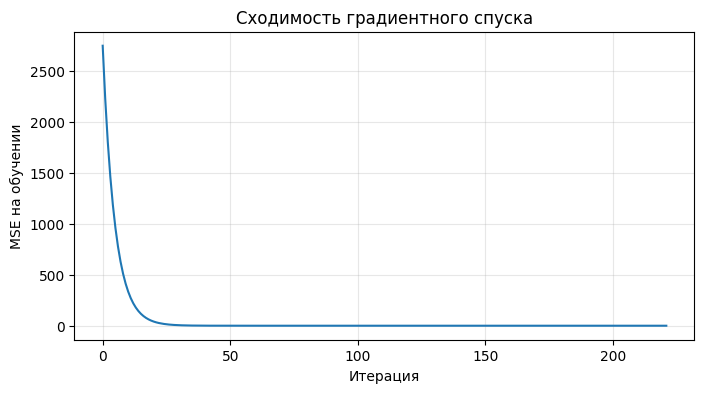

In [6]:
y_pred = X_test_b @ weights

mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test - y_pred))
r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum(
    (y_test - y_test.mean()) ** 2
)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

display(pd.DataFrame({
    "Фактическое значение": y_test[:10],
    "Прогноз": np.round(y_pred[:10], 2)
}))

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Итерация")
plt.ylabel("MSE на обучении")
plt.title("Сходимость градиентного спуска")
plt.grid(alpha=0.3)
plt.show()

Градиентный спуск сошёлся за 222 итерации. Модель объясняет около 98,76% вариации индекса успеваемости на тестовой выборке